In [63]:
# Analysis by Abel Wondem

In [64]:
# Put all required library and package here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import trim_mean


# Import the dataset

In [65]:
# input dataset
# In Google Colab, upload 2nd_assignment.csv to the Files panel first.
data = pd.read_csv('/2nd_assignment.csv')
data.head()


,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138.0,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111.0,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113.0,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117.0,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141.0,64,3,340,128,Bad,38,13,Yes,No


# Shape of dataset

In [66]:
# find the shape of dataset
rows, columns = data.shape
print(f'Rows: {rows}, Columns: {columns}')


Rows: 403, Columns: 11


# Quality of data

## Missing value

In [67]:
# find if there is missing value
print(data.isnull().sum())


Sales          1
CompPrice      1
Income         0
Advertising    0
Population     0
Price          0
ShelveLoc      1
Age            0
Education      0
Urban          1
US             0
dtype: int64


In [68]:
# find the row of missing value
rows_with_missing_values = data[data.isnull().any(axis=1)]
print('rows_with_missing_values =')
print(rows_with_missing_values)


rows_with_missing_values =
     Sales  CompPrice  Income  Advertising  Population  Price ShelveLoc  Age  \
8     6.54      132.0     110            0         108    124       NaN   76   
26     NaN      107.0     115           11         496    131      Good   50   
37    4.95        NaN      41            5         412    110    Medium   54   
109   8.55      134.0     107            0         104    108    Medium   60   

     Education Urban   US  
8           10    No   No  
26          11    No  Yes  
37          10   Yes  Yes  
109         12   NaN   No  


In [69]:
# archive the original dataset
data_missing = data.copy()

# fill quantitative missing values with the median
quantitative_variables = ['Sales','CompPrice','Income','Advertising','Population','Price','Age','Education']
for variable in quantitative_variables:
    data_missing[variable] = data_missing[variable].fillna(data_missing[variable].median())

# fill categorical missing values with the mode
categorical_variables = ['ShelveLoc','Urban','US']
for variable in categorical_variables:
    data_missing[variable] = data_missing[variable].fillna(data_missing[variable].mode()[0])

# double check the missing value after filling
print(data_missing.isnull().sum())

# use the fixed dataset from this point forward
data = data_missing.copy()


Sales          0
CompPrice      0
Income         0
Advertising    0
Population     0
Price          0
ShelveLoc      0
Age            0
Education      0
Urban          0
US             0
dtype: int64


## Duplication

In [70]:
# archive the dataset
data_duplication = data_missing.copy()

# Check if there is duplication
print('Number of duplicated rows:', data_duplication.duplicated().sum())
print(data_duplication[data_duplication.duplicated(keep=False)])


Number of duplicated rows: 3
     Sales  CompPrice  Income  Advertising  Population  Price ShelveLoc  Age  \
72    5.52      115.0      45            0         432    116    Medium   25   
73    5.52      115.0      45            0         432    116    Medium   25   
98    7.45      161.0      82            5         287    129       Bad   33   
99    7.45      161.0      82            5         287    129       Bad   33   
155   5.93      150.0      36            7         488    150    Medium   25   
156   5.93      150.0      36            7         488    150    Medium   25   

     Education Urban   US  
72          15   Yes   No  
73          15   Yes   No  
98          16   Yes  Yes  
99          16   Yes  Yes  
155         17    No  Yes  
156         17    No  Yes  


In [71]:
# drop the duplication
data_duplication = data_duplication.drop_duplicates().reset_index(drop=True)

# double check the duplication
print('Duplicated rows after cleaning:', data_duplication.duplicated().sum())
print('Cleaned shape:', data_duplication.shape)

# use cleaned dataset from this point forward
data = data_duplication.copy()


Duplicated rows after cleaning: 0
Cleaned shape: (400, 11)


## Outliers


In [72]:
# archive the dataset
data_outliers = data.copy()


In [73]:
# create a function to check the outlier
def outlier_check(variable):
    print(f'\nOutlier check for {variable}')

    fig, ax = plt.subplots(figsize=(4, 4))
    ax = sns.boxplot(y=data_outliers[variable], ax=ax)
    ax.set_ylabel(variable)
    ax.set_title(f'Box plot of {variable}')
    plt.show()

    Q1 = data_outliers[variable].quantile(0.25)
    Q3 = data_outliers[variable].quantile(0.75)
    IQR = Q3 - Q1
    outliers = data_outliers[(data_outliers[variable] < Q1 - 1.5*IQR) |
                             (data_outliers[variable] > Q3 + 1.5*IQR)][variable]
    print('Outliers:')
    print(outliers)



Outlier check for Sales


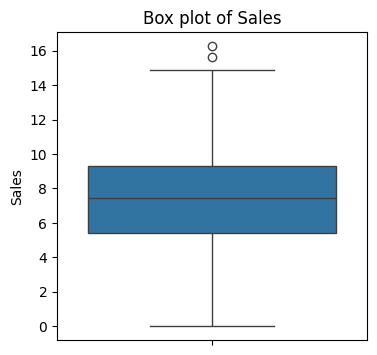

Outliers:
316    15.63
376    16.27
Name: Sales, dtype: float64

Outlier check for CompPrice


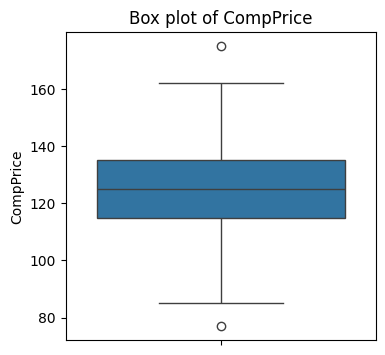

Outliers:
42      77.0
310    175.0
Name: CompPrice, dtype: float64

Outlier check for Income


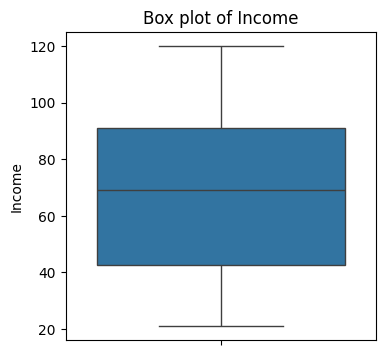

Outliers:
Series([], Name: Income, dtype: int64)

Outlier check for Advertising


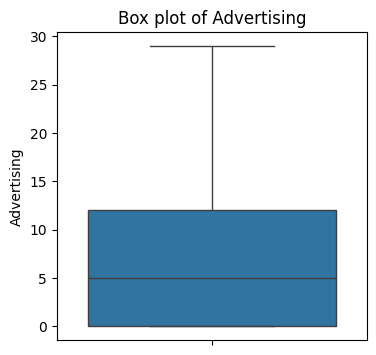

Outliers:
Series([], Name: Advertising, dtype: int64)

Outlier check for Population


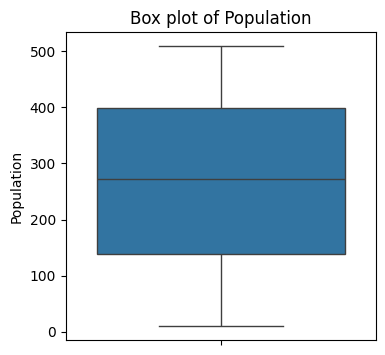

Outliers:
Series([], Name: Population, dtype: int64)

Outlier check for Price


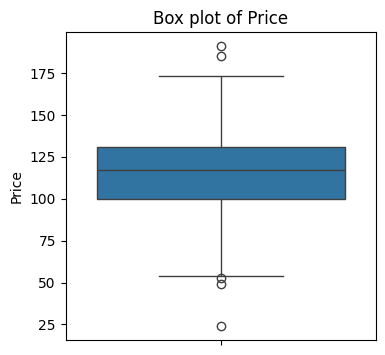

Outliers:
42      24
125     49
165    191
174    185
367     53
Name: Price, dtype: int64

Outlier check for Age


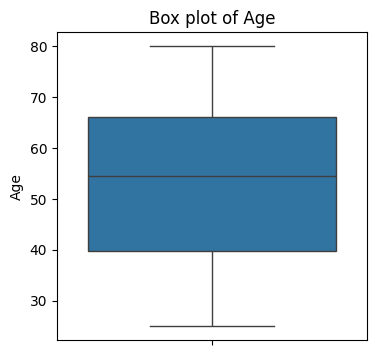

Outliers:
Series([], Name: Age, dtype: int64)

Outlier check for Education


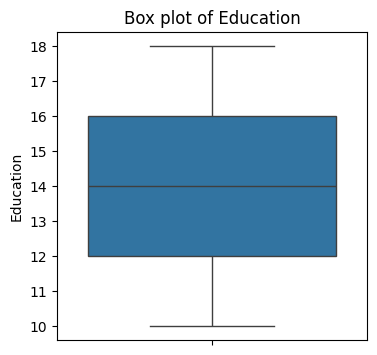

Outliers:
Series([], Name: Education, dtype: int64)


In [74]:
# define the quantitative variables
quantitative_variables = ['Sales','CompPrice','Income','Advertising','Population','Price','Age','Education']

# for loop to check outliers of all quantitative variables
for variable in quantitative_variables:
    outlier_check(variable)


# Data Exploration

In [75]:
# archive the dataset
data_exploration = data.copy()


## Quantitative Variables

In [76]:
# Write a function for quantitative variable exploration
def quan_exploration(dataset, variable):
  # mean
  mean = dataset[variable].mean()
  # trimmed mean (10% from each tail)
  trimmed_mean = trim_mean(dataset[variable], 0.10)
  # median
  median = dataset[variable].median()
  # std
  std = dataset[variable].std()
  # range
  data_range = dataset[variable].max() - dataset[variable].min()
  # IQR
  IQR = dataset[variable].quantile(0.75) - dataset[variable].quantile(0.25)

  print(f'\n{variable}')
  print(f'mean: {mean}')
  print(f'trimmed_mean: {trimmed_mean}')
  print(f'median: {median}')
  print(f'std: {std}')
  print(f'range: {data_range}')
  print(f'IQR: {IQR}')

  fig, ax = plt.subplots(figsize=(4, 4))
  ax = sns.boxplot(y=dataset[variable], ax=ax)
  ax.set_ylabel(variable)
  ax.set_title(f'Box plot of {variable}')
  plt.show()

  # create a new figure and axes for the density histogram
  fig_density, ax_density = plt.subplots(figsize=(4, 4))
  # plot the density histogram
  ax_density = dataset[variable].plot.hist(density=True, alpha=0.5, ax=ax_density)
  dataset[variable].plot.density(ax=ax_density)
  ax_density.set_ylabel('Density/Frequency')
  ax_density.set_title(f'Density histogram of {variable}')
  plt.show()



Sales
mean: 7.494125
trimmed_mean: 7.426656249999999
median: 7.470000000000001
std: 2.823806729485701
range: 16.27
IQR: 3.9299999999999997


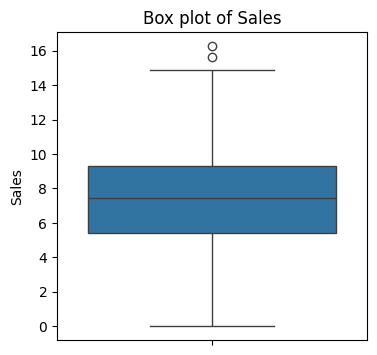

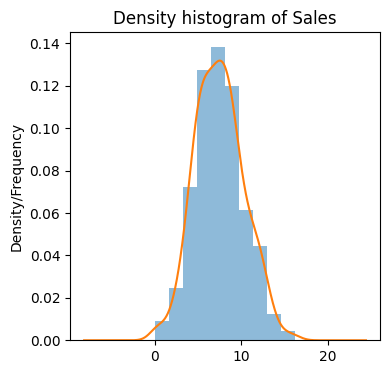


CompPrice
mean: 124.985
trimmed_mean: 125.053125
median: 125.0
std: 15.333217009474861
range: 98.0
IQR: 20.0


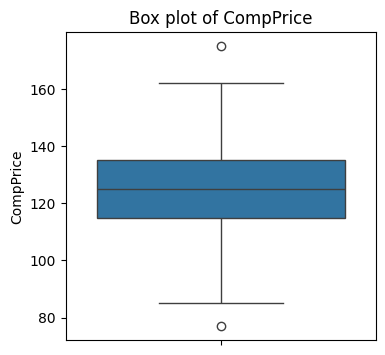

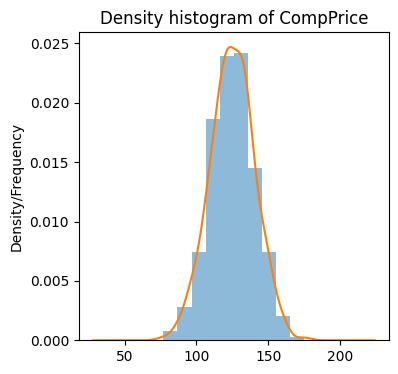


Income
mean: 68.6575
trimmed_mean: 68.259375
median: 69.0
std: 27.986036506593273
range: 99
IQR: 48.25


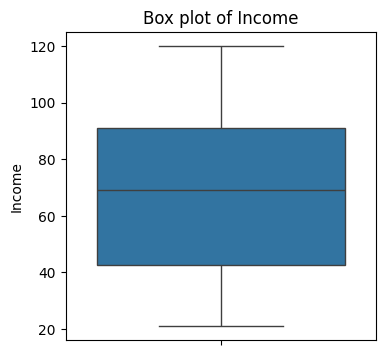

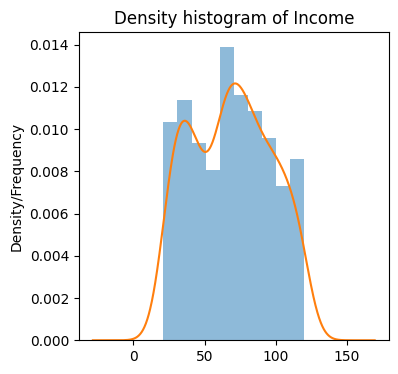


Advertising
mean: 6.635
trimmed_mean: 5.890625
median: 5.0
std: 6.650364152314975
range: 29
IQR: 12.0


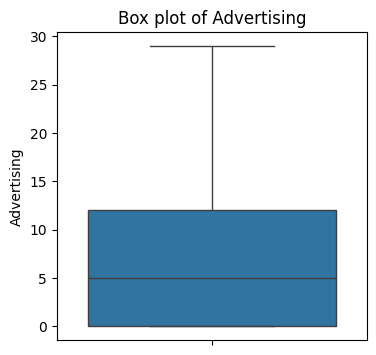

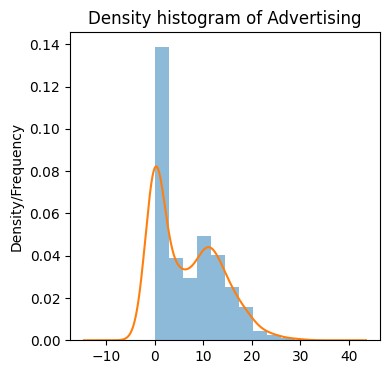


Population
mean: 264.84
trimmed_mean: 265.5625
median: 272.0
std: 147.37643615869223
range: 499
IQR: 259.5


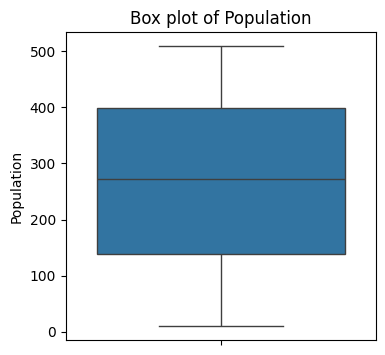

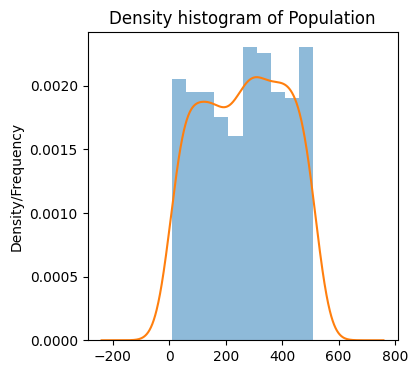


Price
mean: 115.795
trimmed_mean: 115.921875
median: 117.0
std: 23.676664378459755
range: 167
IQR: 31.0


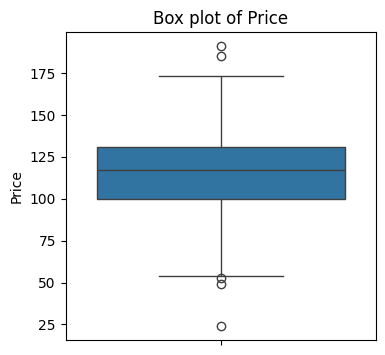

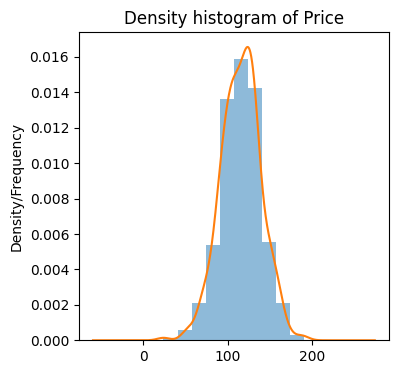


Age
mean: 53.3225
trimmed_mean: 53.484375
median: 54.5
std: 16.200296842789225
range: 55
IQR: 26.25


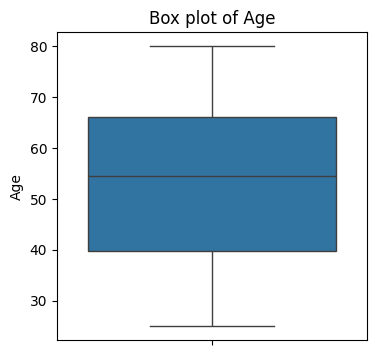

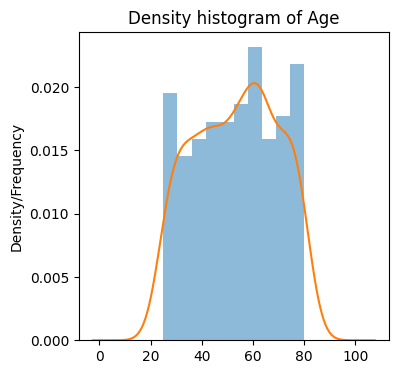


Education
mean: 13.9
trimmed_mean: 13.875
median: 14.0
std: 2.6205281757308976
range: 8
IQR: 4.0


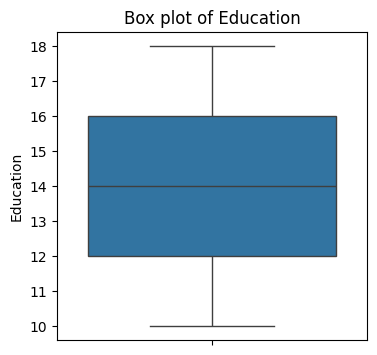

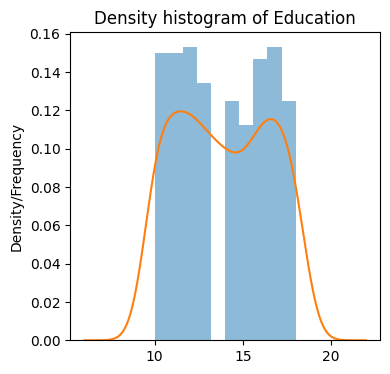

In [77]:
# for loop to explore all quantitative variables
for variable in quantitative_variables:
    quan_exploration(data_exploration, variable)


## Categorical Variables


In [78]:
# Write a function for categorical variable exploration
def cal_exploration(dataset, variable):
  # find the mode of variable
  mode = dataset[variable].mode()[0]

  # find the probability of category
  probability = dataset[variable].value_counts(normalize=True)

  print(f'\nexploration of {variable}')
  print(f'mode: {mode}')
  print(f'probability:\n{probability}')

  # barchart
  fig_bar, ax_bar = plt.subplots(figsize=(4, 4))
  ax_bar = probability.plot(kind='bar', ax=ax_bar)
  ax_bar.set_ylabel('Probability')
  ax_bar.set_title(f'Bar chart of {variable}')
  plt.show()



exploration of ShelveLoc
mode: Medium
probability:
ShelveLoc
Medium    0.5475
Bad       0.2400
Good      0.2125
Name: proportion, dtype: float64


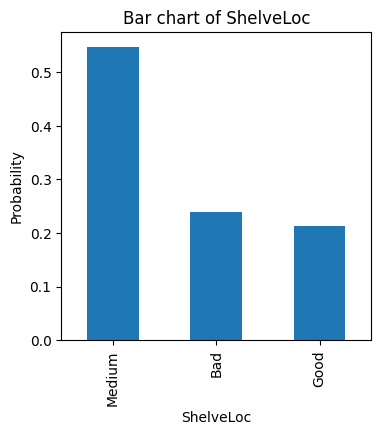


exploration of Urban
mode: Yes
probability:
Urban
Yes    0.705
No     0.295
Name: proportion, dtype: float64


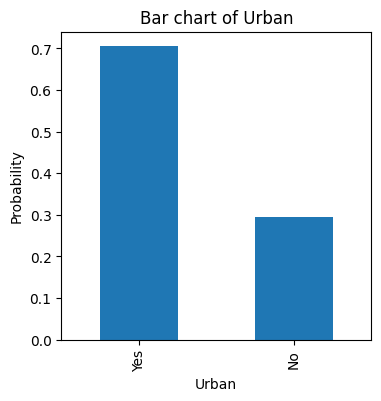


exploration of US
mode: Yes
probability:
US
Yes    0.645
No     0.355
Name: proportion, dtype: float64


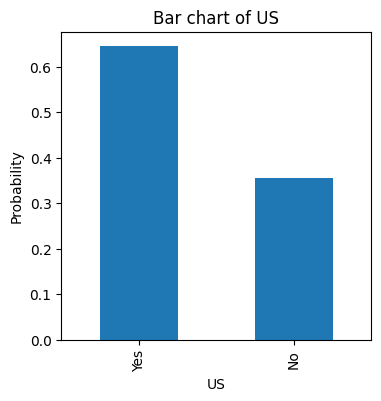

In [79]:
# define the categorical variables
categorical_variables = ['ShelveLoc','Urban','US']

# for loop to explore all categorical variables
for variable in categorical_variables:
    cal_exploration(data_exploration, variable)


## Relationship Exploration

### Quantitative vs. Quantitative

In [80]:
# Write a function for quan vs quan variables exploration
def corr_exploration(dataset, variable_list):
  corr_matrix = dataset[variable_list].corr()
  print(corr_matrix)

  # create a heatmap
  plt.figure(figsize=(8, 6))
  sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
  plt.title('Correlation Matrix')
  plt.show()


                Sales  CompPrice    Income  Advertising  Population     Price  \
Sales        1.000000   0.064418  0.150674     0.269024    0.049251 -0.445501   
CompPrice    0.064418   1.000000 -0.081306    -0.024362   -0.094062  0.584737   
Income       0.150674  -0.081306  1.000000     0.058995   -0.007877 -0.056698   
Advertising  0.269024  -0.024362  0.058995     1.000000    0.265652  0.044537   
Population   0.049251  -0.094062 -0.007877     0.265652    1.000000 -0.012144   
Price       -0.445501   0.584737 -0.056698     0.044537   -0.012144  1.000000   
Age         -0.231681  -0.100220 -0.004670    -0.004557   -0.042663 -0.102177   
Education   -0.051097   0.024226 -0.056855    -0.033594   -0.106378  0.011747   

                  Age  Education  
Sales       -0.231681  -0.051097  
CompPrice   -0.100220   0.024226  
Income      -0.004670  -0.056855  
Advertising -0.004557  -0.033594  
Population  -0.042663  -0.106378  
Price       -0.102177   0.011747  
Age          1.000000   0

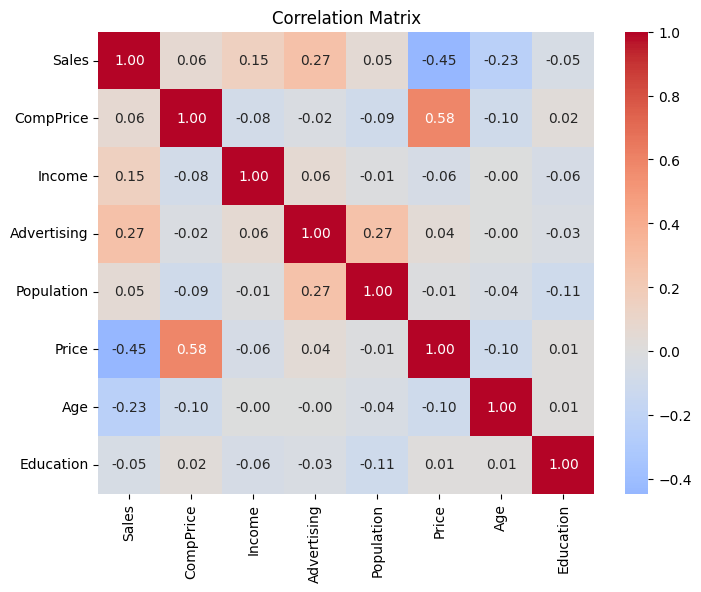

In [81]:
# execute the function
corr_exploration(data_exploration, quantitative_variables)


### Categorical vs. Categorical

In [82]:
# Write a function for cate vs cate variables exploration
def cate_relationship(dataset, variable1, variable2):
  percentage_crosstab = pd.crosstab(dataset[variable1], dataset[variable2], normalize='index')
  return percentage_crosstab


In [83]:
# Write a for loop to execute the function
for i, variable1 in enumerate(categorical_variables):
  for variable2 in categorical_variables[i+1:]:
      print(f'\nrelationship between {variable1} and {variable2}')
      print(cate_relationship(data_exploration, variable1, variable2))



relationship between ShelveLoc and Urban
Urban            No       Yes
ShelveLoc                    
Bad        0.229167  0.770833
Good       0.329412  0.670588
Medium     0.310502  0.689498

relationship between ShelveLoc and US
US               No       Yes
ShelveLoc                    
Bad        0.354167  0.645833
Good       0.282353  0.717647
Medium     0.383562  0.616438

relationship between Urban and US
US           No       Yes
Urban                    
No     0.389831  0.610169
Yes    0.340426  0.659574


### Categorical vs. Quantitative

In [84]:
# Write a function for cate vs quan variables exploration
def cate_quan_exploration(dataset, cate_var, quan_var):
  fig, ax_box = plt.subplots(figsize=(5, 4))
  ax_box = sns.boxplot(x=cate_var, y=quan_var, data=dataset, ax=ax_box)
  ax_box.set_ylabel(quan_var)
  ax_box.set_title(f'{quan_var} by {cate_var}')
  plt.show()



relationship between ShelveLoc and Sales


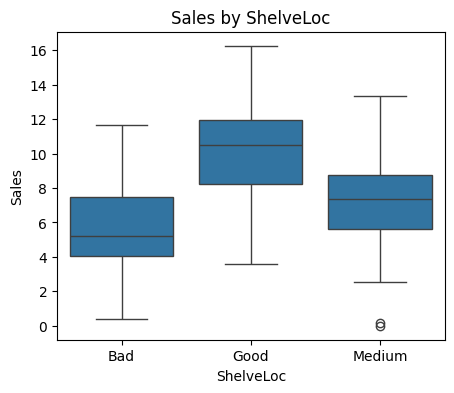


relationship between ShelveLoc and CompPrice


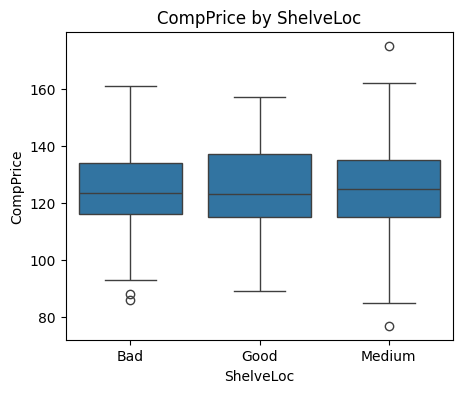


relationship between ShelveLoc and Income


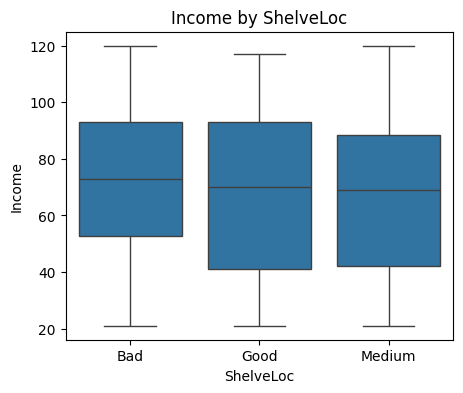


relationship between ShelveLoc and Advertising


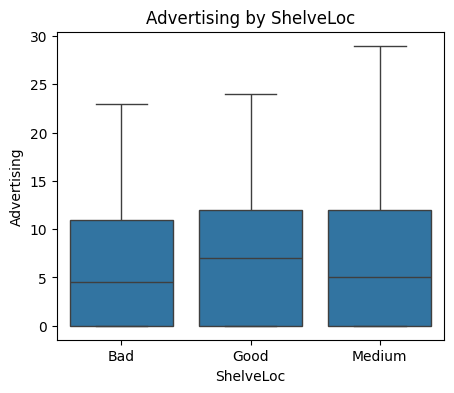


relationship between ShelveLoc and Population


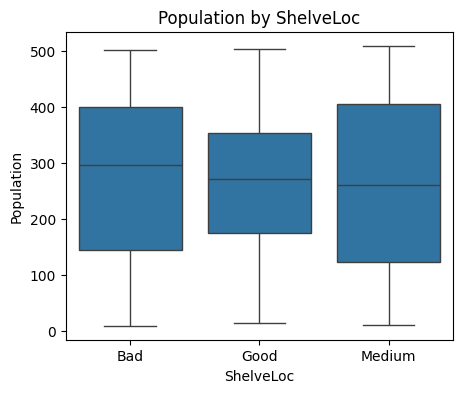


relationship between ShelveLoc and Price


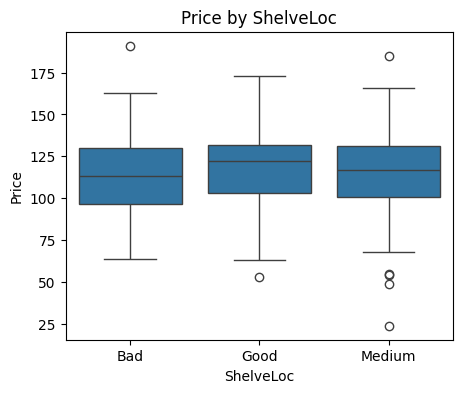


relationship between ShelveLoc and Age


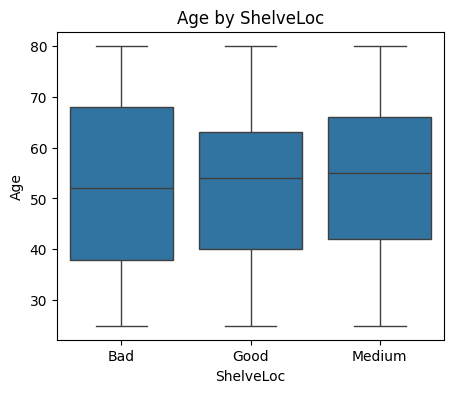


relationship between ShelveLoc and Education


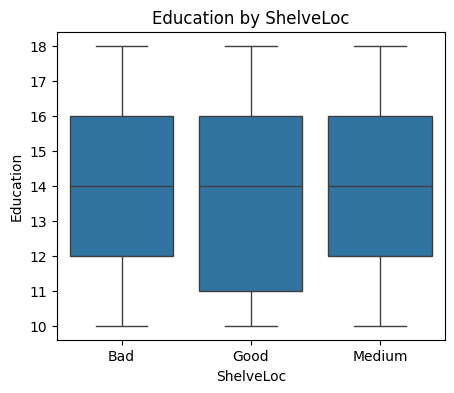


relationship between Urban and Sales


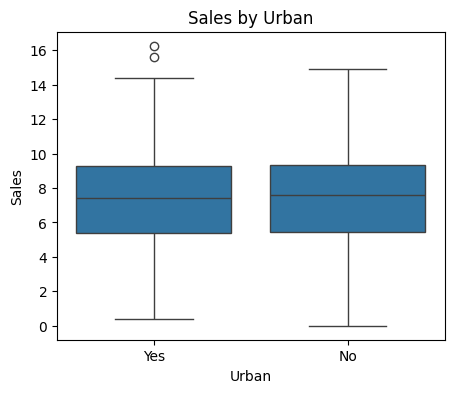


relationship between Urban and CompPrice


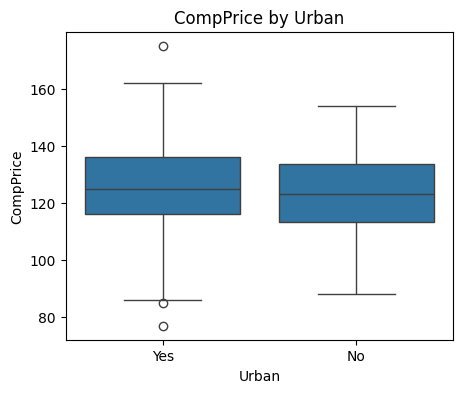


relationship between Urban and Income


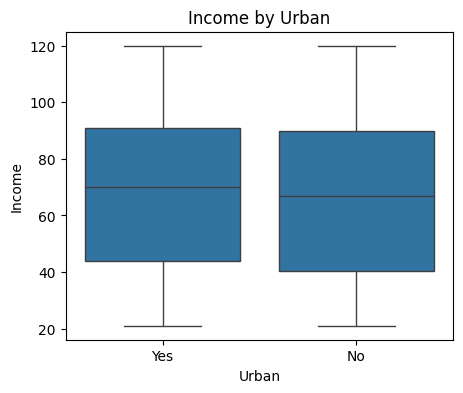


relationship between Urban and Advertising


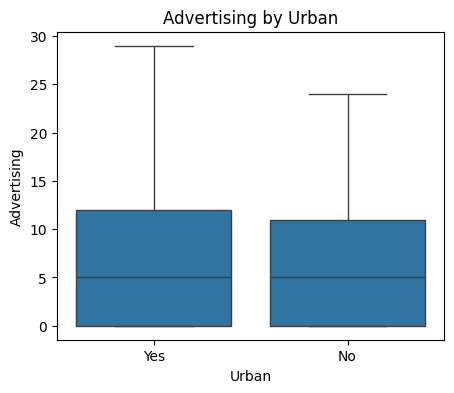


relationship between Urban and Population


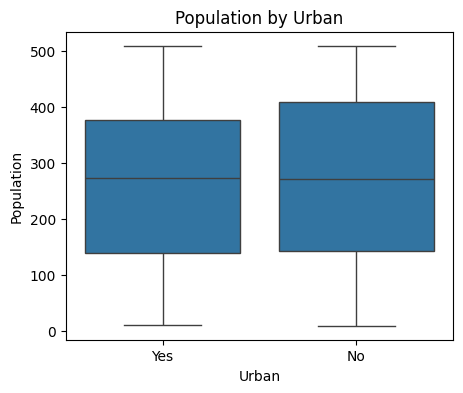


relationship between Urban and Price


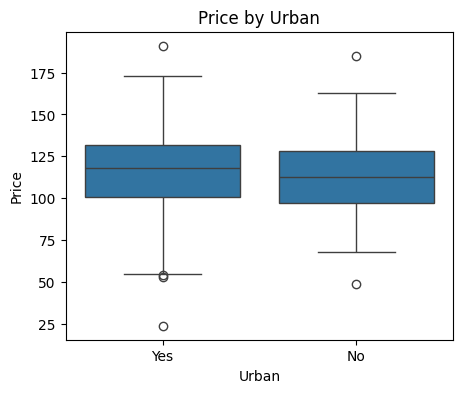


relationship between Urban and Age


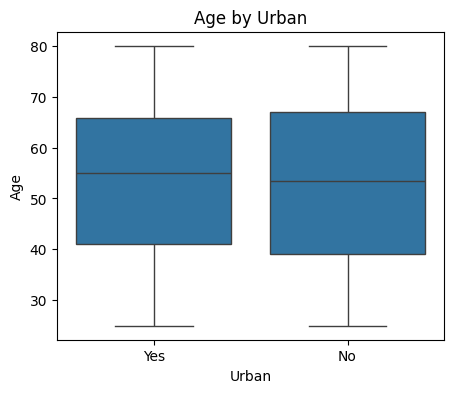


relationship between Urban and Education


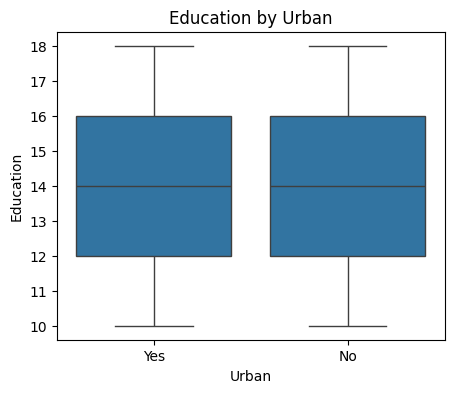


relationship between US and Sales


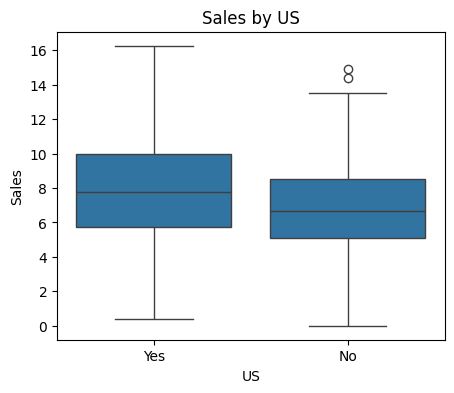


relationship between US and CompPrice


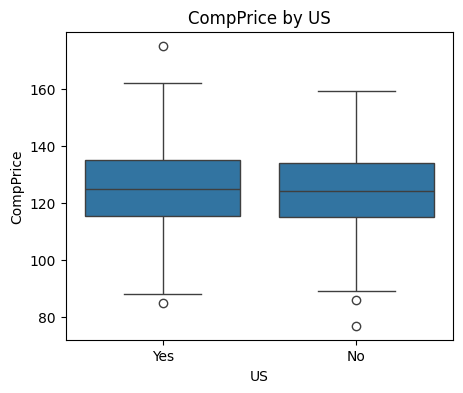


relationship between US and Income


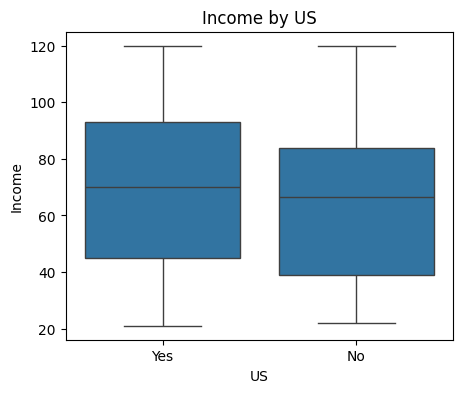


relationship between US and Advertising


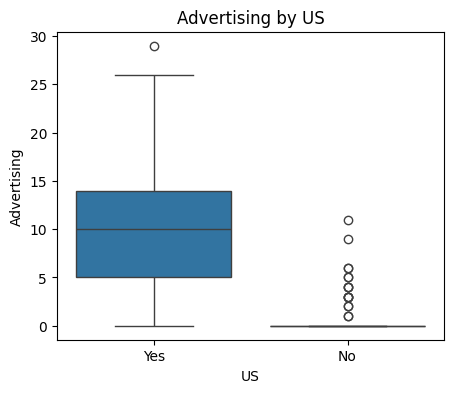


relationship between US and Population


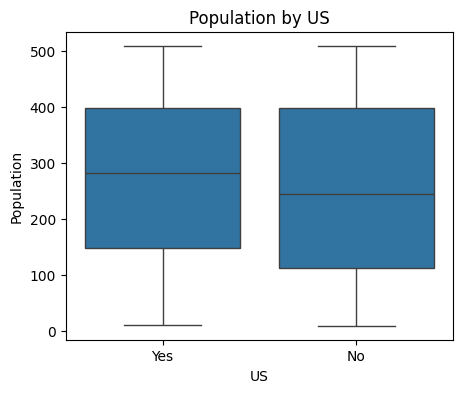


relationship between US and Price


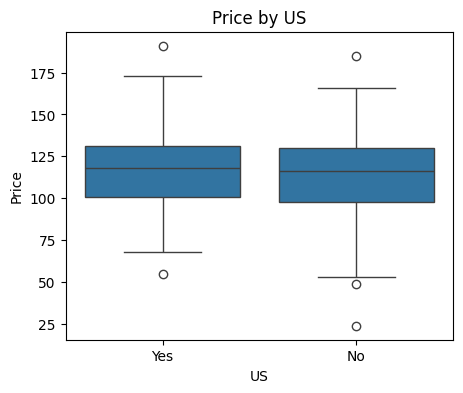


relationship between US and Age


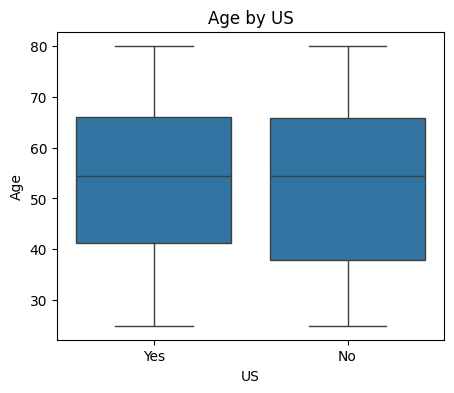


relationship between US and Education


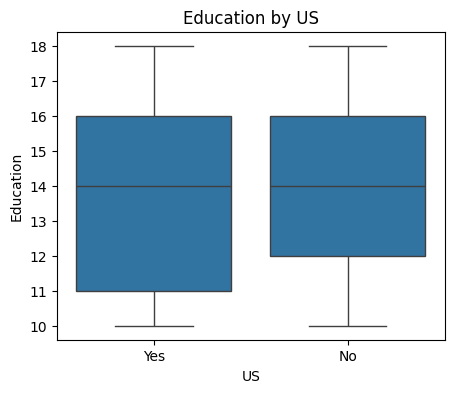

In [85]:
# Write a for loop to execute the function
for cate_var in categorical_variables:
  for quan_var in quantitative_variables:
    print(f'\nrelationship between {cate_var} and {quan_var}')
    cate_quan_exploration(data_exploration, cate_var, quan_var)
